# Quickstart

In this tutorial we grow one tumor with `iscc`, cut the resected specimen in two, and generate one data set for each of bulk whole-genome sequencing (WGS), single-cell DNA sequencing (scDNA), single-cell RNA sequencing (scRNA) and Visium spatial transcriptomics.
Every data set comes with a ground truth that gives the clone, copy number, cell type and niche of each cell it measured, and we read the ground truth next to the data.
The notebook runs in about ten minutes on a laptop.

The other tutorials go deeper into each step.
[Shape the tumor](02_shape_the_tumor.ipynb) changes the tumor through its configuration, [Shape the data](03_shape_the_data.ipynb) changes the assays and their biases, and [Simulate a cohort](04_cohort.ipynb) grows many patients over one configuration.

In [1]:
import os
import warnings
os.environ["KMP_WARNINGS"] = "0"  # silence a deprecation notice of OpenMP in the UMAP dependencies
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="numba")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

from iscc.constants import IMMUNE_SUBTYPES, normal_names
from iscc.data import bulkDNA, scDNA, scRNA, Visium
from iscc.integrations import biological_types, cell_subtypes, clone_summary, clones_from_clades
from iscc.sample import Resection
from iscc.tumor import GenotypeTumor
from iscc.tumor.viz import CNV_CMAP, cnv_norm

## Grow a tumor

We build a [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) from `tutorial_config.yaml`, which is in the folder of the notebooks in the repository ([running the tutorials](https://pedrofale.github.io/iscc/installation/#running-the-tutorials)), and grow it to 25,000 cancer cells.
The configuration describes a field of 96 by 96 demes with five glands in stroma, where a deme is a column of tissue about 50 µm wide that contains a few tens of cells.
The stroma holds T and NK cells, myeloid cells and B and plasma cells, and a cancer cell in the stroma dies at a rate that grows with the share of T and NK cells in the deme.
The founding cancer cells start inside one gland, which keeps them in for 200 generations after it is half full, before they spread to the other glands and invade the stroma.
We pass `materialize=False` because the samples below build their own per-cell tables.

In [2]:
tumor = GenotypeTumor(config="tutorial_config.yaml", seed=7)
tumor.grow(n_steps=2000, target_cancer=25_000, materialize=False)
print(f"{tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations, "
      f"in a field of {tumor.get_tumor_size():,} cells")

25,032 cancer cells after 597 generations, in a field of 161,554 cells


## Look at the tumor

[`plot_tissue`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) draws the field from the cell counts of every deme.
On the left, each deme is colored by its state, where a duct is a gland of the field.
Cancer in a duct corresponds to ductal carcinoma in situ (DCIS), and cancer in the stroma to invasive ductal carcinoma (IDC).
In the middle, each deme with cancer cells is colored by the driver clone that dominates it, where a driver clone is a set of cells with the same mutated driver genes.
On the right, each deme is colored by the share of immune cells among the cells of the deme, and the demes that contain cancer cells are outlined in red.

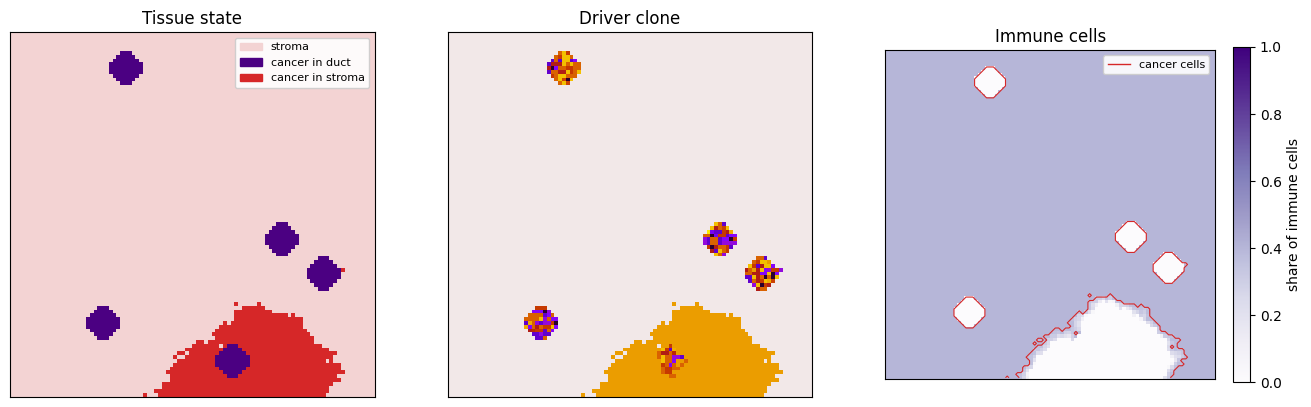

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
tumor.plot_tissue(ax=axes[0], color="state")
tumor.plot_tissue(ax=axes[1], color="clone", min_freq=0.05)
tumor.plot_tissue(ax=axes[2], color="immune")
axes[0].set_title("Tissue state")
axes[1].set_title("Driver clone")
axes[2].set_title("Immune cells")
plt.show()

All five glands contain cancer cells, and the invasive lesion has grown around one gland at the lower edge of the field.
One driver clone dominates the invasive lesion, while each gland contains a mixture of driver clones.
Immune cells make up 0.4 of the cells of every stroma deme and none of the ducts, and they are lost from the invasive lesion, where cancer cells filled the demes.

The driver clones keep their colors in the next two plots, which share the time axis.
[`plot_muller`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) shows the frequency of each driver clone over time, with each clone drawn inside the parent clone.
[`plot_phylogeny`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) draws the same clones as a tree, each clone a branch from the generation it arose to the last generation it had cells, thicker the larger it grew and joined to its parent clone where it arose.
A letter marks where a lineage gained a heritable trait, for the gains whose descendants hold at least 1% of the cancer cells at the end, and a dotted line marks when the founding acinus opened.
Driver clones that never reach 5% of the cancer cells are merged into their parent.

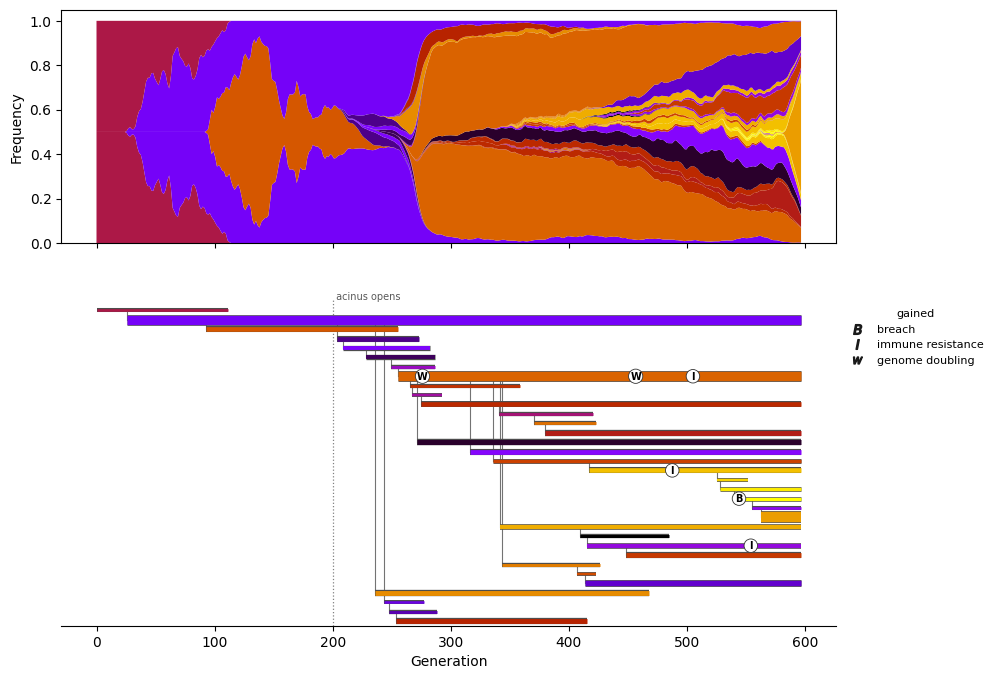

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
tumor.plot_muller(ax=axes[0], by_drivers=True, min_freq=0.05)
tumor.plot_phylogeny(ax=axes[1], min_freq=0.05)
axes[0].set_xlabel("")
plt.show()

The founder clone was replaced within about 110 generations, and a chain of driver clones followed while the lesion was confined to its acinus.
After the acinus opened at generation 200, many clones arose within about 60 generations as the lesion spread through the glands, and the clone that arose at about generation 255 grew to most of the cancer cells, with lineages that doubled their genome (W) and gained immune resistance (I).
A lineage gained breach at about generation 545 (B), and the clone that arose from it shortly after grew in the stroma into the invasive lesion, so that every cancer cell of the stroma descends from that gain.

## Cut the specimen

We take the whole field as the resected specimen and cut it with a [`Resection`](https://pedrofale.github.io/iscc/reference/Resection/).
An in-plane cut (`bisect`) splits the specimen into a left and a right part, along the column at the center of the cancer demes, which runs through the lesion.
We dissociate the left part into a suspension of cells for the sequencing assays, and we take a thin section of the right part (`slice`) for Visium.
The section keeps half of the cells of each deme (`depth_frac=0.5`), the half-depth section of the paper.
`max_cells` keeps a representative subsample of 8,000 cells of the left part, as a sequencing run takes a subsample of a suspension, and caps the section at 60,000 cells, above the number of cells it holds.
With `install=True` the sample becomes the cell table of the tumor, which the ground-truth functions of `iscc.integrations` read.

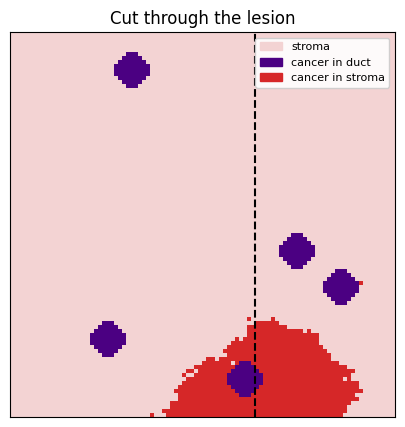

dissociated sample: 8,151 cells | Visium section: 31,481 cells


In [5]:
specimen = Resection(tumor)
column = np.mean([deme % tumor.grid_size for deme in specimen.cancer_region(margin=0)])
frac = round(column / tumor.grid_size, 2)
left, right = specimen.bisect(frac=frac, axis="x")
sample = specimen.dissociate(left, max_cells=8000, install=True, seed=0)
section = specimen.slice(right, depth_frac=0.5, max_cells=60_000, layers="visium")

ax = tumor.plot_tissue(color="state", figsize=(5, 5))
ax.axvline(int(frac * tumor.grid_size) - 0.5, color="k", ls="--")
ax.set_title("Cut through the lesion")
plt.show()
print(f"dissociated sample: {len(sample['cell_type']):,} cells | Visium section: {len(section['cell_type']):,} cells")

## Read the ground truth

The table `sample["cell_type"]` gives the genotype of each cell, and `cell_subtypes` turns the genotype into the cell type, with the immune and stromal cells by subtype (`biological_types` gives one type for all immune cells and one for all stromal cells).
The table `sample["cell_gland"]` gives the gland of each cell, or -1 for a cell in the stroma, and we call gland or stroma the niche of the cell.

In [6]:
cell_type = pd.Series(cell_subtypes(sample["cell_type"]["cell_id"]), index=sample["cell_type"].index)
niche = pd.Series(np.where(sample["cell_gland"]["gland_id"] >= 0, "gland", "stroma"), index=cell_type.index)
pd.crosstab(cell_type.rename("cell type"), niche.rename("niche"))

niche,gland,stroma
cell type,,
B_plasma,0,320
PVL,0,1160
T_NK,0,1615
cancer,573,329
endothelial,0,1692
epithelial,272,0
fibroblast,0,1370
myeloid,0,820


Of the 902 cancer cells of the sample, 573 are in glands and 329 in the stroma.
The sample also holds 2,755 immune cells (T and NK cells, myeloid cells, and B and plasma cells) and 4,222 stromal cells (fibroblasts, endothelial cells and perivascular cells, PVL), all from the stroma.

[`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/) labels each cancer cell with a clone, which is a clade of the true genealogy that contains at least 50 of the sampled cells.
Cancer cells above every such clade share the label `other`, and normal cells have no clone.
[`clone_summary`](https://pedrofale.github.io/iscc/reference/clone_summary/) describes each clone by the number of cells, the mutated oncogenes and tumor suppressor genes (TSGs), the division rate and the levels of the two invasion traits, breach and stromal survival.

In [7]:
clones = clones_from_clades(tumor, min_cells=50)
clone_summary(tumor, clones)[["n_cells", "n_mut_onc", "n_mut_tsg", "division_rate", "breach", "stromal_survival"]].round(3)

,n_cells,n_mut_onc,n_mut_tsg,division_rate,breach,stromal_survival
clone,,,,,,
clone_1,425,3,2,2.0,0.0,0.0
clone_2,126,3,1,2.0,0.0,0.0
clone_3,85,3,1,2.0,0.0,0.0
clone_4,73,2,3,2.0,0.0,0.0
clone_5,69,4,3,2.0,0.0,0.0
other,124,<NA>,<NA>,NaN,NaN,NaN


The sample contains five clones and 124 cancer cells outside every clade.
The traits of a clone are those of the deepest genotype that all the sampled cells of the clone share, so a trait that arose within a clone does not show here.
The division rate of every clone is at the ceiling of 2.0 per generation set by `max_birth_rate`.
None of the clones carries breach or stromal survival at that level, although 329 of the 902 sampled cancer cells are in the stroma, since breach arose within clone 1, below the genotype its cells share (B in the tree).

## Bulk DNA

[`bulkDNA`](https://pedrofale.github.io/iscc/reference/bulkDNA/) pools the cells of the sample into one library, by default at the depth of WGS, and reports the reads and the alternate reads at every locus.
The ground truth of the assay includes the purity of the pool, which is the fraction of cancer cells in it.
A clonal heterozygous mutation in diploid cancer cells is expected at a variant allele frequency (VAF) of half the purity, and the germline variants at 0.5 and 1.

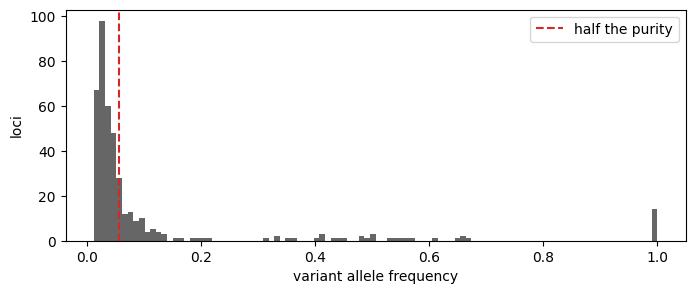

purity of the pool: 0.11


In [8]:
bulk = bulkDNA().run(sample)
vaf = bulk.observed_data.query("alt_counts > 0")["vaf"]

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(vaf, bins=100, color="0.4")
ax.axvline(bulk.purity / 2, color="tab:red", ls="--", label="half the purity")
ax.set_xlabel("variant allele frequency")
ax.set_ylabel("loci")
ax.legend()
plt.show()
print(f"purity of the pool: {bulk.purity:.2f}")

The pool has a purity of 0.11, since most cells of the left part are normal.
Most mutated loci have a VAF at or below half the purity, as expected for clonal and subclonal mutations, and the germline variants spread around 0.5 and group at 1.

## Single-cell DNA

[`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) sequences 500 cells of the sample one by one, with the uneven amplification and the allelic dropout of single-cell WGS.
We sum the reads of each cell over each of the 12 segments of the genome and scale them to a mean of 2 per cell, which is a rough copy number estimate.
We show the estimate next to the true copy number of the same cells, ordered by their label, so that the clones come first, then the normal cells, and last the cancer cells outside every clade.

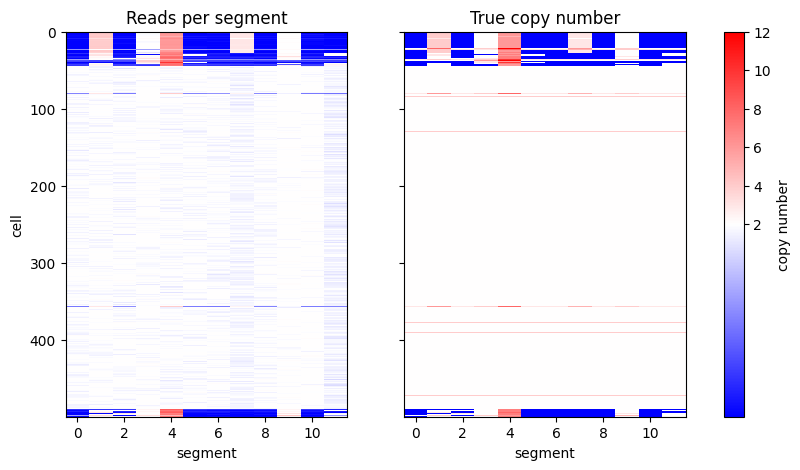

clone
clone_1     27
clone_2      4
clone_3      5
clone_4      4
clone_5      4
normal     445
other       11


In [9]:
dna = scDNA(n_cells=500).run(sample)
adata_dna = dna.to_anndata()
segment = adata_dna.var["segment"].values
label = clones.reindex(adata_dna.obs_names).astype(object).fillna("normal")
order = label.sort_values(kind="stable").index

reads = pd.DataFrame(adata_dna.X, index=adata_dna.obs_names).T.groupby(segment).sum().T
estimate = 2 * reads.div(reads.mean(axis=1), axis=0)
truth = pd.DataFrame(adata_dna.layers["true_cn"], index=adata_dna.obs_names).T.groupby(segment).mean().T

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
norm = cnv_norm(truth.values)
for ax, values, title in zip(axes, (estimate, truth), ("Reads per segment", "True copy number")):
    im = ax.imshow(values.loc[order].values, aspect="auto", cmap=CNV_CMAP, norm=norm, interpolation="none")
    ax.set_title(title)
    ax.set_xlabel("segment")
axes[0].set_ylabel("cell")
fig.colorbar(im, ax=axes, label="copy number")
plt.show()
print(label.value_counts().sort_index().to_string())

Of the 500 cells, 55 are cancer cells, which reflects the purity of the sample.
The estimate from the reads recovers the copy number changes of the cancer cells, such as the gains of segments 1 and 4 and the losses of segments 0, 2, 5, 6 and 8, and the estimates of the normal cells stay close to 2.
[Shape the data](03_shape_the_data.ipynb) shows how to set the amplification and depth of the assay.

## Single-cell RNA

[`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) draws unique molecular identifier (UMI) counts for 2,000 cells of the sample with the 10x Genomics preset.
The column `clone` of the assay gives the genotype of each cell, which we replace by the clone label.
We then run the standard scanpy workflow and color the cells by their true cell type, with the immune and stromal cells by subtype, and by their clone and niche.

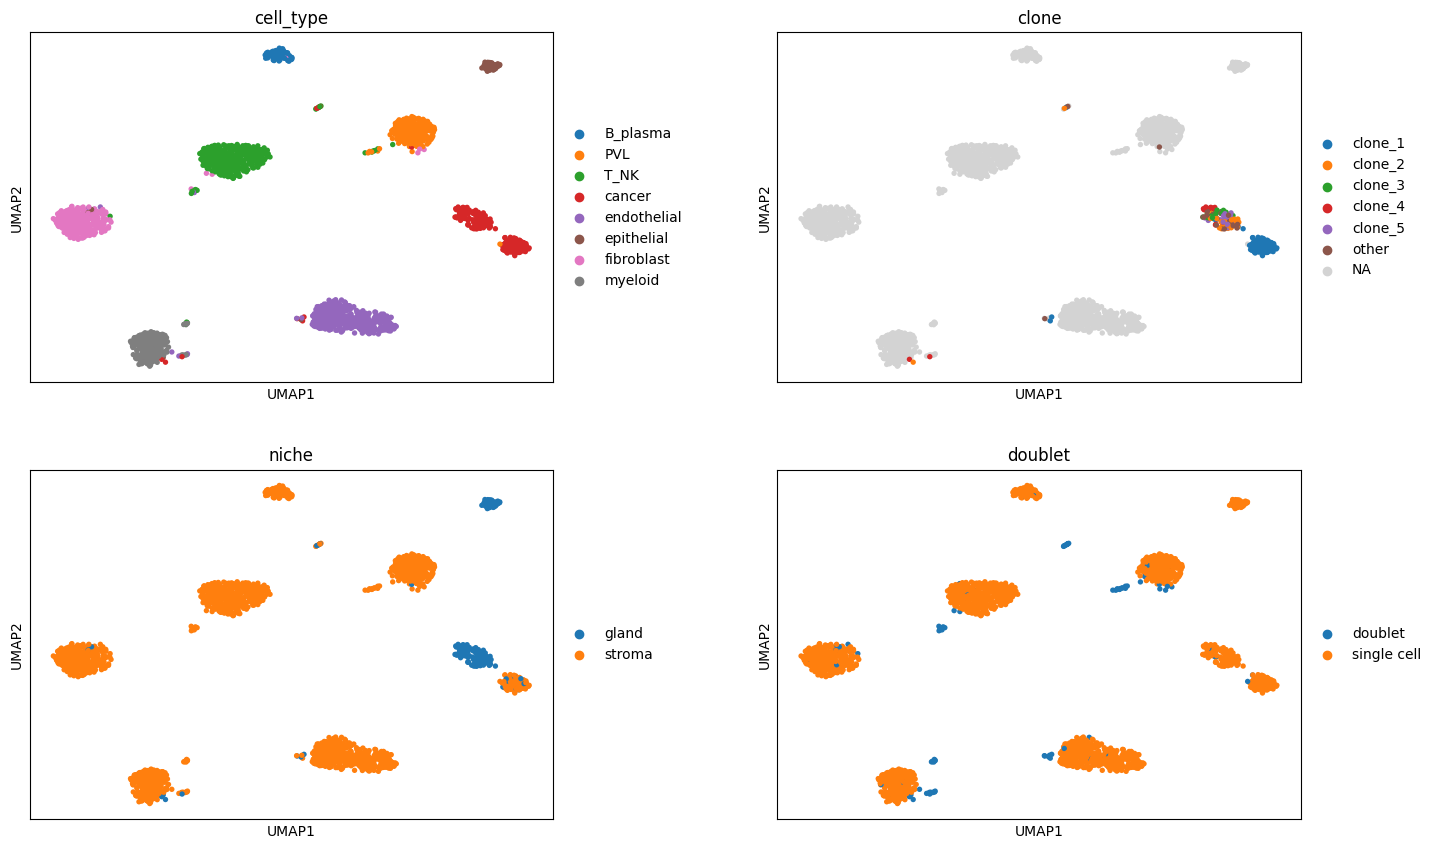

niche,gland,stroma
clone,,
clone_1,20,96
clone_2,36,0
clone_3,22,0
clone_4,17,0
clone_5,17,0
other,30,0


In [10]:
rna = scRNA(n_cells=2000).run(sample)
adata_rna = rna.to_anndata()
adata_rna.obs["cell_type"] = cell_subtypes(adata_rna.obs["clone"])
adata_rna.obs["clone"] = clones.reindex(adata_rna.obs_names).values
adata_rna.obs["niche"] = niche.reindex(adata_rna.obs_names).values

sc.pp.normalize_total(adata_rna)
sc.pp.log1p(adata_rna)
sc.pp.pca(adata_rna)
sc.pp.neighbors(adata_rna)
sc.tl.umap(adata_rna)
adata_rna.obs["doublet"] = adata_rna.obs["is_doublet"].map({True: "doublet", False: "single cell"})
sc.pl.umap(adata_rna, color=["cell_type", "clone", "niche", "doublet"], ncols=2, wspace=0.3)
pd.crosstab(adata_rna.obs["clone"], adata_rna.obs["niche"])

The fibroblasts, endothelial cells, perivascular cells and epithelial cells form one cluster each, as does each immune subtype, and the doublets of two different cell types form small clusters of their own.
The cancer cells form two clusters, which separate the cancer cells of the stroma, all of clone 1, from the cancer cells of the glands.
Clone 1, the only clone with cells in the stroma, is the clone of the invasive lesion.

## Visium

[`Visium`](https://pedrofale.github.io/iscc/reference/Visium/) lays the 4,992 spots of a Visium v1 slide over the section and counts the UMIs of the cells under each spot.
The section is already thin, so `section_frac=1.0` keeps all of its cells.
The ground truth of a spot includes the share of each genotype among the cells under it, from which we compute the fraction of cancer cells and of immune cells.
We keep the spots that cover tissue and color them by their UMI count and by their true fractions of cancer cells and of immune cells.

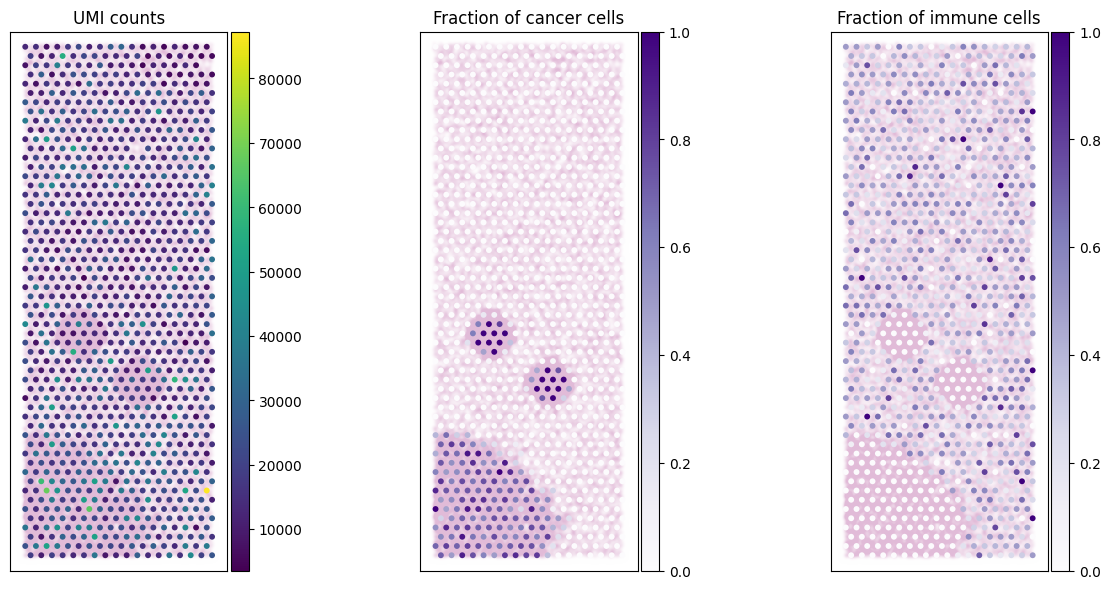

1,006 spots on tissue, median 7 cells per spot
median UMI count: 22,920 in the 134 spots with mostly cancer cells, 17,471 in the others


In [11]:
visium = Visium(section_frac=1.0, seed=0).run(section)
adata_vis = visium.to_anndata()
adata_vis.obs["cancer_fraction"] = [sum(share for genotype, share in shares.items() if genotype not in normal_names)
                                    for shares in visium.clone_fracs]
adata_vis.obs["immune_fraction"] = [sum(share for genotype, share in shares.items() if genotype in IMMUNE_SUBTYPES)
                                    for shares in visium.clone_fracs]
adata_vis = adata_vis[adata_vis.obs["in_tissue"] == 1].copy()
library = list(adata_vis.uns["spatial"])[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 7))
sq.pl.spatial_scatter(adata_vis, color="total_counts", library_id=library, img=True, img_alpha=0.3, shape="circle",
                      ax=axes[0], fig=fig, title="UMI counts")
sq.pl.spatial_scatter(adata_vis, color="cancer_fraction", library_id=library, img=True, img_alpha=0.3, shape="circle",
                      cmap="Purples", ax=axes[1], fig=fig, title="Fraction of cancer cells")
sq.pl.spatial_scatter(adata_vis, color="immune_fraction", library_id=library, img=True, img_alpha=0.3, shape="circle",
                      cmap="Purples", ax=axes[2], fig=fig, title="Fraction of immune cells")
xy = adata_vis.obsm["spatial"] * adata_vis.uns["spatial"][library]["scalefactors"]["tissue_hires_scalef"]
pad = 0.03 * np.ptp(xy, axis=0).max()
for ax in axes:                                  # zoom on the spots of the section
    ax.set(xlim=(xy[:, 0].min() - pad, xy[:, 0].max() + pad), ylim=(xy[:, 1].max() + pad, xy[:, 1].min() - pad),
           xlabel="", ylabel="")
plt.show()
print(f"{adata_vis.n_obs:,} spots on tissue, median {adata_vis.obs['n_cells'].median():.0f} cells per spot")
cancerous = adata_vis.obs["cancer_fraction"] > 0.5
print(f"median UMI count: {adata_vis.obs.loc[cancerous, 'total_counts'].median():,.0f} in the {cancerous.sum()} spots "
      f"with mostly cancer cells, {adata_vis.obs.loc[~cancerous, 'total_counts'].median():,.0f} in the others")

The spots of the two glands in the section contain mostly cancer cells, and the spots of the lesion contain a mixture of cancer cells and normal cells.
Immune cells are found in the spots of the stroma and not in those of the glands and of the lesion.
The 134 spots with mostly cancer cells have a median of 22,920 UMIs, against 17,471 in the other spots.
The depth of a spot follows the capture field of the slide and not the cells under it, so this difference reflects where the field is high, and another `seed` of the assay moves it.

## Next steps

The tool tutorials run a standard method on each data set and score it against the ground truth, for example [copy number from scDNA with HMMcopy](tool_hmmcopy.ipynb), [purity, copy number and clones from bulk WGS with ASCAT and PyClone-VI](tool_ascat_pyclonevi.ipynb) and [cell-type deconvolution of Visium spots with RCTD](tool_rctd.ipynb).